# Validation — compare postprocessed batch against published deposit

Analysis below reads `postproc/<TAG>/point.zarr` and checks it against the Beerling et al. (2025) outputs in `USA_ERW/data` across runs and years.

The point coordinate in `point.zarr` is the same key as the published pickles (we aren't matching sites or using a nearest-neighbor lookup, etc).

**We compare five published quantities that have a model counterpart.**

| deposit file | column | model field | conversion needed |
|---|---|---|---|
| `compiled_run_CO2` | t CO2 per point per year | `cdr` | ÷ area, cumulative sum |
| `compiled_run_pH` | topsoil pH | `pH_col` | none |
| `compiled_run_rock` | t rock per point per year | `rock` | ÷ area, cumulative sum |
| `compiled_run_P_mass` | P release per year | `P_mass` | cumulative sum |
| `compiled_run_K_mass` | K release per year | `K_mass` | cumulative sum |

The "conversion needed" column refers to the conversion required to ensure an apples-to-apples comparison between our simulated outputs and the published counterpart. 

We also compare particle size `p80` and the 7-layer initial soil pH `pH0`, though note that these are inputs rather than model results.

The nine remaining deposit files (`grem`, `trem`, `spem`, `grco`, `trco`, `spco`, `feem_*`, `feco_*`) are logistics and cost layers applied on top of the column geochemistry model. We ignore them here because they do not affect the gross CDR or geochemistry results.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, xarray as xr
import matplotlib as mpl, matplotlib.pyplot as plt
from beerling_analysis import io

mpl.rcParams.update({"font.size": 10, "figure.dpi": 120, "axes.grid": False})
OI = dict(blue="#0072B2", vermillion="#D55E00", green="#009E73",
          orange="#E69F00", purple="#CC79A7", sky="#56B4E9", grey="0.45")

TAG      = "e0-conus-1gt"    # the batch to validate
ROOT     = "s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension"
POSTPROC = os.environ.get("BEERLING_POSTPROC", f"{ROOT}/postproc/{TAG}")

ds   = xr.open_zarr(f"{POSTPROC}/point.zarr").load()
SCEN = int(str(ds.attrs["scenario"]).lstrip("S"))
COL  = f"S{SCEN}_U1_N2_p100"          # N2 = the central member; N1/N3 bracket it
S    = lambda a: np.array([str(x).strip() for x in np.asarray(a)])   # zarr hands back StringDType

print(f"{POSTPROC}/point.zarr")
print(f"  {ds.sizes['point']:,} points over {int(ds.cluster.to_series().nunique())} clusters, "
      f"{ds.sizes['time']} years ({int(ds.time[0])}-{int(ds.time[-1])})")
print(f"  scenario {ds.attrs['scenario']}, experiment {ds.attrs['experiment']}, "
      f"{ds.area_ha.sum().item()/1e6:.2f} M ha")
print(f"  published column {COL}")

s3://carbonplan-carbon-removal/ew-workflows-data/beerling-2025-model-extension/postproc/e0-conus-1gt/point.zarr
  2,322 points over 221 clusters, 51 years (2020-2070)
  scenario S1, experiment E0, 24.49 M ha
  published column S1_U1_N2_p100


## 1. Premise checks — is each simulation the one its points were assigned?

Before we compare model outputs, we first confirm that our simulations and the published records cover the same thing (i.e., same sites and inputs). The initial pH check is useful because it is reported in the published clusters which we then pass to points, so it offers validation that our cluster to point hand-off is working as we'd expect. 

The `p80` is a weaker check because it is set to 100 microns everywhere (but still important to get right because of the sensitivity of the output to the initial feedstock particle size). 

In [3]:
db  = io.load_published("CO2")
pts = list(ds.point.values)
assert all(int(p) in db for p in pts), "some points are not keys of the published pickle"

get = lambda p, f: np.atleast_1d(db[int(p)][f]).ravel()
pub_meta = pd.DataFrame({
    "area_ha":   [float(db[int(p)]["ar"]) for p in pts],
    "recipient": [str(db[int(p)]["nam_l"]).strip() for p in pts],
    "crop":      [str(get(p, "nam")[0]).strip() for p in pts],
    "source":    [str(get(p, "bas")[SCEN - 1]).strip().replace(" ", "_") for p in pts],
    "start":     [int(get(p, "yy")[SCEN - 1]) for p in pts],
    "p80":       [float(get(p, "p80")[0]) for p in pts],
}, index=pts)
pub_pH0 = np.array([np.asarray(db[int(p)]["pH0"], float).ravel() for p in pts])

for name, v, how in [
        ("area (ha)",         np.abs(pub_meta.area_ha.values - ds.area_ha.values).max(), "max |dif|"),
        ("p80 (um)",          np.abs(pub_meta.p80.values - ds.p80.values).max(), "max |dif|"),
        ("initial pH0",       np.abs(pub_pH0 - ds.pH0.values).max(), "max |dif|"),
        ("first application", np.abs(pub_meta.start.values - ds.start_year.values).max(), "max |dif| yr")]:
    print(f"  {name:20s} {how:12s} {v:.3e}   {'OK' if v < 1e-9 else 'MISMATCH'}")
    assert v < 1e-9, f"{name} disagrees between the run and the published record"

for name, ours, theirs in [("recipient state", ds.recipient_state, pub_meta.recipient),
                           ("crop (point)",    ds.crop,            pub_meta.crop),
                           ("crop (inps)",     ds.sim_crop,        pub_meta.crop),
                           ("source state",    ds.source_state,    pub_meta.source)]:
    bad = int((S(ours.values) != S(theirs.values)).sum())
    print(f"  {name:20s} {'mismatches':12s} {bad:>9d}   {'OK' if bad == 0 else 'MISMATCH'}")
    assert bad == 0, f"{name} disagrees"

print(f"\nall {len(pts):,} points: same soil, same rock, same schedule, same crop.")

  area (ha)            max |dif|    0.000e+00   OK
  p80 (um)             max |dif|    0.000e+00   OK
  initial pH0          max |dif|    0.000e+00   OK
  first application    max |dif| yr 0.000e+00   OK
  recipient state      mismatches           0   OK
  crop (point)         mismatches           0   OK
  crop (inps)          mismatches           0   OK
  source state         mismatches           0   OK

all 2,322 points: same soil, same rock, same schedule, same crop.


### Comparing simulations requires cluster-level analysis

The model runs once per cluster, and that cluster's results are copied to every point that the cluster encompasses. That is, the per-hectare series should be identical across a cluster's points (within rounding error). This check just confirms that our understanding holds --- within the published deposit, sites that come from the same cluster match to machine precision. (Note, this doesn't compare our results to the published results).

In [4]:
cl  = pd.Series(ds.cluster.values, index=pts)
co2 = np.array([db[int(p)]["CO2_a_b"][COL].values for p in pts]) / pub_meta.area_ha.values[:, None]

spread = pd.DataFrame(co2, index=cl.values).groupby(level=0).agg(
    lambda g: np.nanmax(np.abs(g - g.iloc[0])) / max(np.abs(g.iloc[0]).max(), 1e-30))
worst, sizes = float(np.nanmax(spread.values)), cl.value_counts()
print(f"{len(sizes)} clusters, {sizes.min()}-{sizes.max()} points each (median {int(sizes.median())})")
print(f"worst within-cluster spread of published per-hectare CDR: {worst:.2e}")
assert worst < 1e-9, "published per-hectare CDR varies within a cluster -- it should not"

221 clusters, 1-28 points each (median 10)
worst within-cluster spread of published per-hectare CDR: 4.42e-16


## 2. Mapping the published counterpart to our data structure

We build one xr.ds from the published deposit that mirrors `point.zarr`. Per-point CO2 and rock totals are divided by area to create fluxes. `ds` is NaN outside a point's deployment window — and NaN everywhere for any point whose cluster is missing a mineralogy. 

In [5]:
FLUXES = {"cdr": ("CO2", True, True), "pH_col": ("pH", False, False),
          "rock": ("rock", True, True), "P_mass": ("P_mass", False, True),
          "K_mass": ("K_mass", False, True)}      # (deposit file, per-area, cumulative)

_PUB = {"CO2": db}
def published(flux, column=COL):
    d = _PUB.setdefault(flux, io.load_published(flux))
    key, k0 = f"{flux}_a_b", next(iter(d))
    yrs = np.array([int(str(x)[:4]) for x in d[k0][key].index])
    a = np.array([d[int(p)][key][column].values for p in pts])
    return xr.DataArray(a, dims=("point", "time"), coords=dict(point=pts, time=yrs))

mask = ds.cdr.notnull()

def counterpart(column=COL):
    out = {}
    for name, (flux, per_area, cumulative) in FLUXES.items():
        a = published(flux, column)
        if per_area:
            a = a / ds.area_ha
        if cumulative:
            a = a.cumsum("time")
        out[name] = a.sel(time=ds.time).where(mask)
    return xr.Dataset(out)

pub    = counterpart()
ours   = ds[list(pub.data_vars)].where(mask)
lo, hi = counterpart(f"S{SCEN}_U1_N1_p100"), counterpart(f"S{SCEN}_U1_N3_p100")

print(f"{int(mask.sum()):,} point-years compared, {int(mask.any('time').sum()):,} of "
      f"{ds.sizes['point']:,} points have a simulation")
print(f"published N1-N3 spread on 2070 cumulative CDR: "
      f"{float(((hi.cdr - lo.cdr) / pub.cdr).sel(time=2070).median()) * 100:.0f}% of N2 "
      f"(median point) -- the deposit's own uncertainty, for scale")

60,330 point-years compared, 2,322 of 2,322 points have a simulation
published N1-N3 spread on 2070 cumulative CDR: 50% of N2 (median point) -- the deposit's own uncertainty, for scale


## 3. Validation across output vars at-a-glance

We set tolerances that define our comfort with treating the variables as practically the same. For comulative quantities, tolerances are set to 10E-3 of the run's total (0.1 percent error). For pH, the tolerance is set to 0.01 pH units (about 1 percent of the modeled pH change under ERW). Each error in the figure below is expressed as a fraction of the prescribed tolerance. 

Note that `cumulative CDR` evaluates the difference in the time-integrated value, whereas `CDR over time (annual)` evaluates the difference in the CDR timeseries (i.e., every cluster at every year). The rock applied error is much lower than the others largely because it is a model input, not an output. 

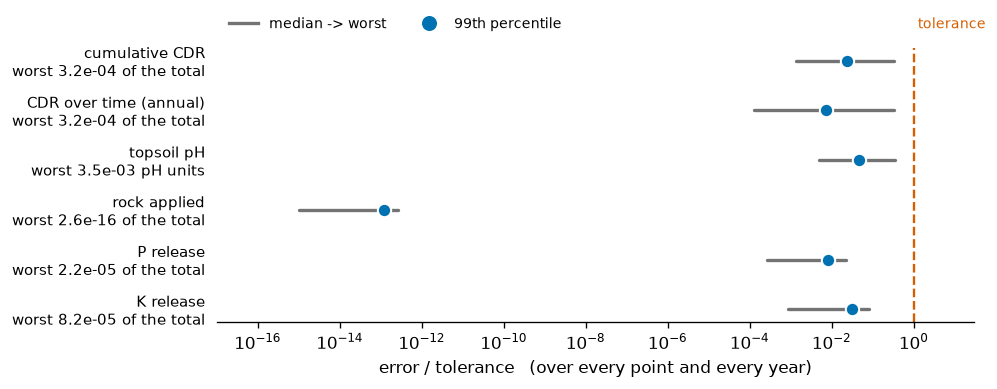

              median       p99       max       tol
cdr        1.325e-06 2.391e-05 3.232e-04 1.000e-03
cdr_annual 1.238e-07 7.376e-06 3.232e-04 1.000e-03
pH_col     4.940e-05 4.559e-04 3.476e-03 1.000e-02
rock       0.000e+00 1.184e-16 2.584e-16 1.000e-03
P_mass     2.681e-07 8.136e-06 2.230e-05 1.000e-03
K_mass     8.312e-07 3.015e-05 8.219e-05 1.000e-03

PASS -- every quantity is inside tolerance at every point and every year


In [6]:
TOL   = {"cdr": 1e-3, "cdr_annual": 1e-3, "pH_col": 1e-2,
         "rock": 1e-3, "P_mass": 1e-3, "K_mass": 1e-3}
UNIT  = {k: "share of the run's total" for k in TOL} | {"pH_col": "pH units"}
SHORT = {k: "of the total" for k in TOL} | {"pH_col": "pH units"}
LABEL = {"cdr": "cumulative CDR", "cdr_annual": "CDR over time (annual)",
         "pH_col": "topsoil pH", "rock": "rock applied",
         "P_mass": "P release", "K_mass": "K release"}

annual = lambda x: x - x.shift(time=1).fillna(0.0)
def error(a, b, scale):
    d = np.abs(a - b)
    return d if scale is None else d / np.abs(scale).max("time")

E = {k: error(ours[k], pub[k], None if k == "pH_col" else pub[k]) for k in pub.data_vars}
E["cdr_annual"] = error(annual(ours.cdr), annual(pub.cdr), pub.cdr)
E = {k: E[k] for k in TOL}                         # fixed order, top to bottom

stats = pd.DataFrame({k: dict(median=float(v.median()), p99=float(v.quantile(.99)),
                              max=float(v.max()), tol=TOL[k]) for k, v in E.items()}).T

fig, ax = plt.subplots(figsize=(8.4, 3.4))
y = np.arange(len(stats))[::-1]
for yi, (k, r) in zip(y, stats.iterrows()):
    ax.plot([max(r["median"], 1e-18) / r.tol, r["max"] / r.tol], [yi, yi], color=OI["grey"],
            lw=2, solid_capstyle="round", zorder=2)
    ax.plot(max(r["p99"], 1e-18) / r.tol, yi, "o", ms=8, color=OI["blue"], zorder=3,
            markeredgecolor="white", markeredgewidth=1.2)
ax.axvline(1, color=OI["vermillion"], lw=1.4, ls="--", zorder=1)
ax.text(1, len(stats) - .35, " tolerance", color=OI["vermillion"], fontsize=8.5, ha="left")
ax.plot([], [], color=OI["grey"], lw=2, label="median -> worst")
ax.plot([], [], "o", ms=8, color=OI["blue"], label="99th percentile")
ax.set_xscale("log"); ax.set_xlim(1e-17, 30)
ax.set_yticks(y, [f"{LABEL[k]}\nworst {stats['max'][k]:.1e} {SHORT[k]}" for k in stats.index],
              fontsize=9)
ax.set_xlabel("error / tolerance   (over every point and every year)")
ax.legend(frameon=False, fontsize=8.5, loc="upper left", ncol=2, bbox_to_anchor=(0, 1.16))
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout(); plt.show()

fails = stats[stats["max"] > stats.tol]
print(stats.to_string(float_format=lambda x: f"{x:.3e}"))
print("\nPASS -- every quantity is inside tolerance at every point and every year"
      if fails.empty else f"\nFAIL on: {list(fails.index)}")

## 4. Zooming in on each comparison

This section plots one figure for each output quantity evaluated above with the following three panels: 

- **left** - the three clusters with the largest error between our results and the published series. 
- **middle** - error in the var over time with one line per cluster. 
- **right** - CDF of error across all clusters (simulations). We want to see the CDF reach 1 to the left of the tolerance line. 

In [8]:
rep = np.unique(ds.cluster.values, return_index=True)[1]      # one point per cluster

def compare(k, series, series_pub, title):
    e = E[k]
    per_point = e.max("time").values
    ok = np.isfinite(per_point)                # a cluster missing a mineralogy has no run
    # worst three CLUSTERS: points in a cluster are the same simulation, so ranking
    # points would draw the same run three times.
    order = rep[np.argsort(-np.where(ok[rep], per_point[rep], -np.inf))[:3]]
    fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.5))

    ax = axes[0]
    for j, i in enumerate(order):
        c = [OI["blue"], OI["green"], OI["purple"]][j]
        t = series.isel(point=i).dropna("time")
        ax.plot(t.time, t, color=c, lw=1.8, zorder=3,
                label=f"drv{int(ds.cluster[i])} {S([ds.source_state.values[i]])[0].replace('_', ' ')}")
        p = series_pub.isel(point=i).dropna("time")
        ax.plot(p.time, p, ls="none", marker="o", ms=4.5, mfc="none", mec=c, mew=1.1, zorder=4)
    ax.plot([], [], ls="none", marker="o", ms=4.5, mfc="none", mec=OI["grey"], mew=1.1,
            label="published")
    ax.set_xlabel("year"); ax.set_ylabel(title)
    ax.set_title("the three worst clusters, drawn against\nthe published series", fontsize=8.5)
    ax.legend(frameon=False, fontsize=7.2)

    ax = axes[1]
    ax.plot(e.time, e.isel(point=rep).T, color=OI["grey"], lw=.4, alpha=.35)
    ax.plot(e.time, e.median("point"), color=OI["blue"], lw=1.8, label="median point")
    ax.plot(e.time, e.max("point"), color=OI["vermillion"], lw=1.2, label="worst point")
    ax.axhline(TOL[k], color=OI["vermillion"], lw=1.2, ls="--")
    ax.set_yscale("log"); ax.set_xlabel("year")
    ax.set_ylabel(f"error  ({UNIT[k]})")
    ax.set_title("error against time, one line per cluster", fontsize=8.5)
    ax.legend(frameon=False, fontsize=7.5, loc="lower right")

    ax = axes[2]
    v = np.sort(np.maximum(per_point[ok], 1e-18))
    ax.plot(v, np.arange(1, len(v) + 1) / len(v), color=OI["blue"], lw=2)
    ax.axvline(TOL[k], color=OI["vermillion"], lw=1.2, ls="--")
    ax.text(TOL[k], .06, " tolerance", color=OI["vermillion"], fontsize=8, rotation=90)
    ax.set_xscale("log"); ax.set_xlim(right=max(TOL[k] * 4, v.max() * 4)); ax.set_ylim(0, 1.04)
    ax.set_xlabel(f"worst error over the run  ({UNIT[k]})")
    ax.set_ylabel("fraction of points")
    ax.set_title(f"{int((per_point[ok] <= TOL[k]).sum()):,} of {int(ok.sum()):,} simulated "
                 f"points inside tolerance", fontsize=8.5)

    for a in axes:
        for s in ("top", "right"): a.spines[s].set_visible(False)
    fig.suptitle(LABEL[k], fontsize=11, x=.005, ha="left")
    plt.tight_layout(rect=(0, 0, 1, .95)); plt.show()
    print(f"{LABEL[k]:26s} median {float(e.median()):.2e}   worst {float(e.max()):.2e} "
          f"{UNIT[k]}   (tolerance {TOL[k]:.0e})")

### 4.1 Cumulative CDR

Time-integrated gross CDR accumulated over time after the first rock application.

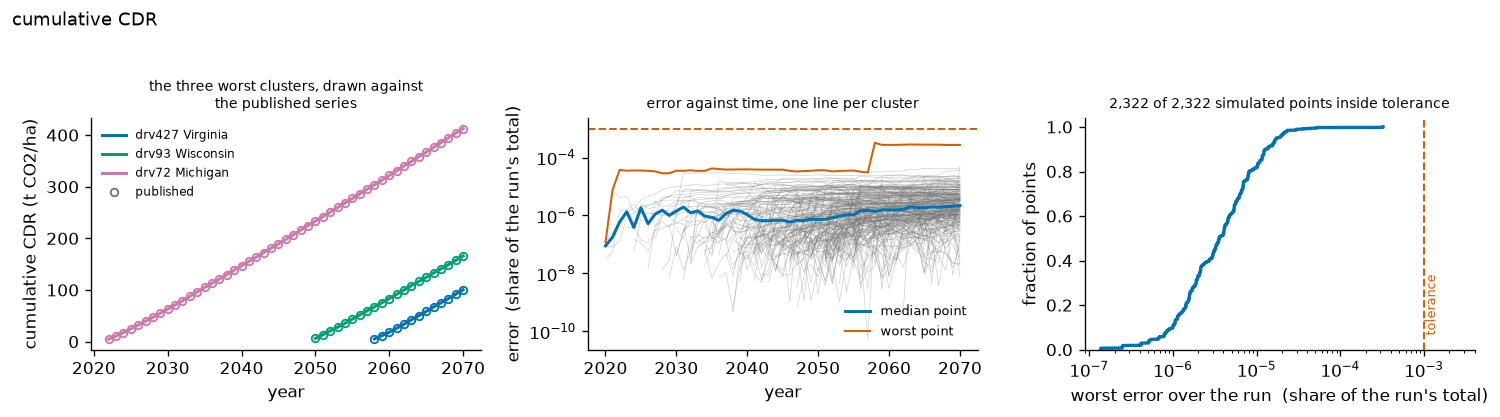

cumulative CDR             median 1.32e-06   worst 3.23e-04 share of the run's total   (tolerance 1e-03)
efficiency at 2070 (t CO2 / t rock)  worst relative error 2.73e-04   range 0.151-0.301


In [9]:
compare("cdr", ours.cdr, pub.cdr, "cumulative CDR (t CO2/ha)")

c2b_o = (ours.cdr / ours.rock).sel(time=2070)
c2b_p = (pub.cdr / pub.rock).sel(time=2070)
print(f"efficiency at 2070 (t CO2 / t rock)  worst relative error "
      f"{float((np.abs(c2b_o - c2b_p) / c2b_p).max()):.2e}   "
      f"range {float(c2b_p.min()):.3f}-{float(c2b_p.max()):.3f}")

### 4.2 Cumulative CDR disagreement in more detail

Compared to other accumulated quantities, cumulative CDR's worst points sit furthest above round-off (floating point) error. This section digs more into the shape of the error to check if anything suspicious falls out. 

We find that most clusters differ by a roughly constant fraction of a few parts per million. The error is relatively flat from the start to the simulation. This is what we'd roughly expect for a cumulative series reassembled from rounded annual increments. 

A few clusters' errors start high and decay down. These reflect a fixed offset (at most 0.03 t CO2/ha, about 0.6% of that year's CDR). Because the offset is fixed rather than compounding, error decays over time as the offset becomes a smaller fraction of cumulative CDR. 

**What causes these errors?**
We think they are likely subtle differences in the published model's first simulated year and ours. The full initial state isn't published so we could not confirm this. But we ruled out a few other possibilities:

- **Mixing weight, `w`.** We don't think that the errors are caused by using the wrong feedstock mixing weights --- we found that no constant `w` could remove the offsets. 
- **Time alignment.** The strong agreement in rock application indicates that our year *k* is aligned with the deposit's (i.e. no off-by-one errors).
- **Annual increments.** After the first year, the changes over time agree quite closely (i.e., the curves are broadly separated by some constant).

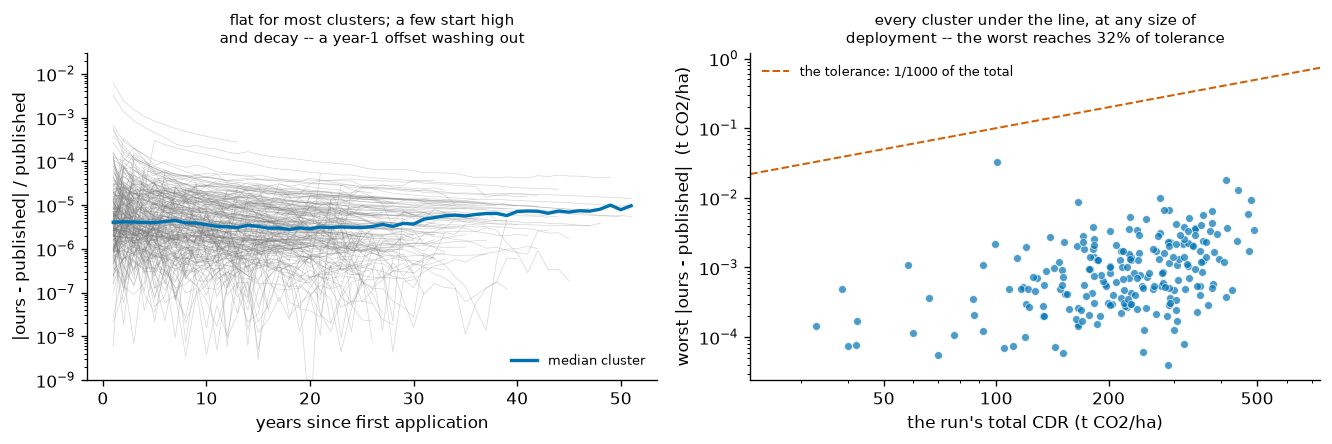

worst clusters -- |dif| in t CO2/ha; the last column is the relative error of the
annual increments from year 2 on

 cluster     state        w  w refit  max |dif|  with refit w  inc after yr 1
     427  Virginia 0.779817 0.776765  0.0324783     0.0273142     0.000809053
      72  Michigan 0.430556 0.430811  0.0178666     0.0146947     0.000364245
      23 Wisconsin 0.846154 0.846241  0.0131512     0.0109464      0.00166535
     194     Idaho 0.406619 0.406238 0.00990031    0.00441109     0.000397403
     148 Minnesota 0.829545 0.828635 0.00931474    0.00521552     0.000344713


In [10]:
full = xr.open_zarr(f"{POSTPROC}/full.zarr").load()
frac = (np.abs(ours.cdr - pub.cdr) / pub.cdr).isel(point=rep).values
absd = np.abs(ours.cdr - pub.cdr).max("time").isel(point=rep).values
tot  = pub.cdr.max("time").isel(point=rep).values
age  = [r[np.isfinite(r)] for r in frac]

fig, axes = plt.subplots(1, 2, figsize=(11.2, 3.8))

ax = axes[0]
for v in age:
    ax.plot(np.arange(1, len(v) + 1), np.maximum(v, 1e-18), color=OI["grey"], lw=.4, alpha=.3)
pad = np.full((len(age), max(len(v) for v in age)), np.nan)
for i, v in enumerate(age):
    pad[i, :len(v)] = v
ax.plot(np.arange(1, pad.shape[1] + 1), np.nanmedian(pad, 0), color=OI["blue"], lw=2,
        label="median cluster")
ax.set_yscale("log"); ax.set_ylim(1e-9, 3e-2)
ax.set_xlabel("years since first application")
ax.set_ylabel("|ours - published| / published")
ax.set_title("flat for most clusters; a few start high\nand decay -- a year-1 offset washing out",
             fontsize=9)
ax.legend(frameon=False, fontsize=8, loc="lower right")

ax = axes[1]
lim = np.array([np.nanmin(tot) / 1.5, np.nanmax(tot) * 1.5])
ax.plot(lim, lim * 1e-3, color=OI["vermillion"], lw=1.2, ls="--",
        label="the tolerance: 1/1000 of the total")
ax.scatter(tot, np.maximum(absd, 1e-18), s=22, color=OI["blue"], alpha=.7,
           edgecolor="white", linewidth=.5)
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(*lim)
ax.xaxis.set_major_locator(mpl.ticker.LogLocator(subs=(1., 2., 5.)))
ax.xaxis.set_major_formatter(mpl.ticker.ScalarFormatter())
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("the run's total CDR (t CO2/ha)")
ax.set_ylabel("worst |ours - published|  (t CO2/ha)")
ax.set_title(f"every cluster under the line, at any size of\ndeployment -- the worst reaches "
             f"{100 * np.nanmax(absd / (tot * TOL['cdr'])):.0f}% of tolerance", fontsize=9)
ax.legend(frameon=False, fontsize=8, loc="upper left")

for a in axes:
    for s in ("top", "right"): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

rows = []
for i in np.argsort(-np.nan_to_num(absd))[:5]:
    c  = int(ds.cluster.values[rep][i])
    a  = full.cdr.sel(cluster=c, feedstock=1).values
    b  = full.cdr.sel(cluster=c, feedstock=2).values
    n2 = pub.cdr.isel(point=rep[i]).values
    m  = np.isfinite(a) & np.isfinite(b) & np.isfinite(n2)
    a, b, n2 = a[m], b[m], n2[m]
    w0  = float(ds.w.values[rep][i])
    wls = float(np.sum((a - b) * (n2 - b)) / np.sum((a - b) ** 2))   # best constant w
    mix = w0 * a + (1 - w0) * b
    inc = np.abs(np.diff(mix) - np.diff(n2)) / np.diff(n2)           # year 2 onward
    rows.append({"cluster": c, "state": S([ds.source_state.values[rep][i]])[0],
                 "w": w0, "w refit": wls,
                 "max |dif|": np.abs(mix - n2).max(),
                 "with refit w": np.abs(wls * a + (1 - wls) * b - n2).max(),
                 "inc after yr 1": inc.max()})
print("worst clusters -- |dif| in t CO2/ha; the last column is the relative error of the\n"
      "annual increments from year 2 on\n")
print(pd.DataFrame(rows).to_string(index=False, float_format=lambda x: f"{x:.6g}"))

### 4.3 CDR over time

The published `CO2` file is annual, so there could be errors in where continuous CDR lands relative to the calendar year.

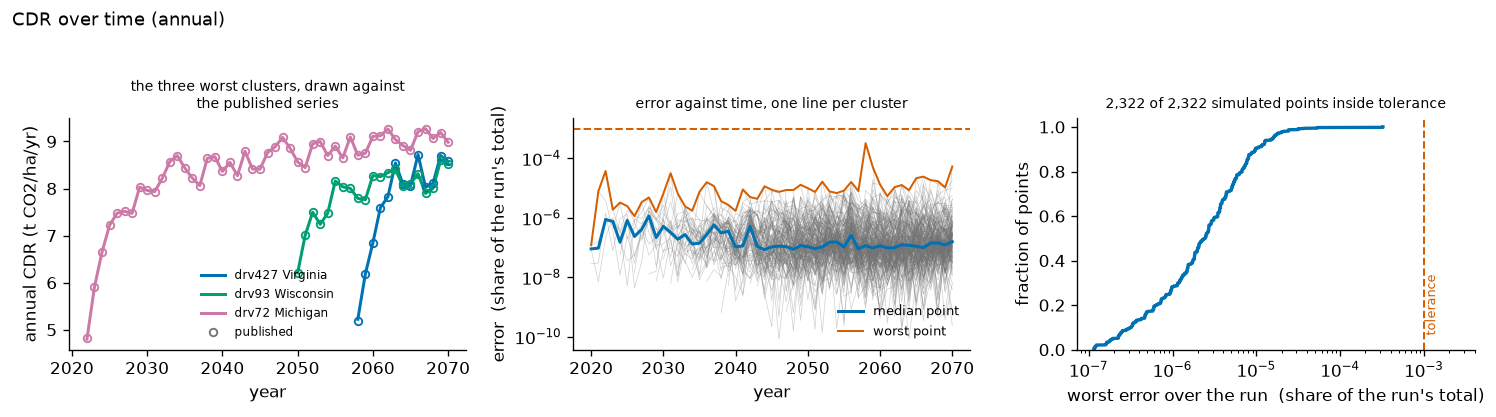

CDR over time (annual)     median 1.24e-07   worst 3.23e-04 share of the run's total   (tolerance 1e-03)


In [11]:
compare("cdr_annual", annual(ours.cdr), annual(pub.cdr), "annual CDR (t CO2/ha/yr)")

### 4.4 pH over time

We compare pH in the 0-15 cm column mean. This is the same reduction from `run_simple4.m:39`, which is distinct from the "top 10 cm" pH metric listed in the deposit's readme (using just the top 10 cm gives a consistent ~0.2 pH unit bias).

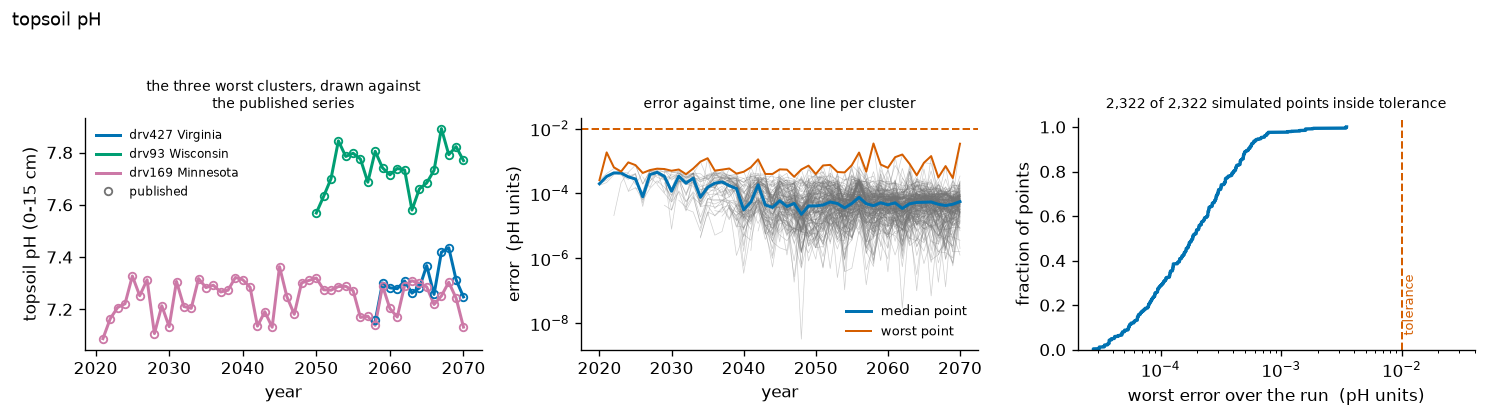

topsoil pH                 median 4.94e-05   worst 3.48e-03 pH units   (tolerance 1e-02)


In [12]:
compare("pH_col", ours.pH_col, pub.pH_col, "topsoil pH (0-15 cm)")

### 4.5 Rock applied

This is a deterministic schedule, so it should align within floating point round-off error. Because it's an input, it's not a test of our ability to reproduce the model results.

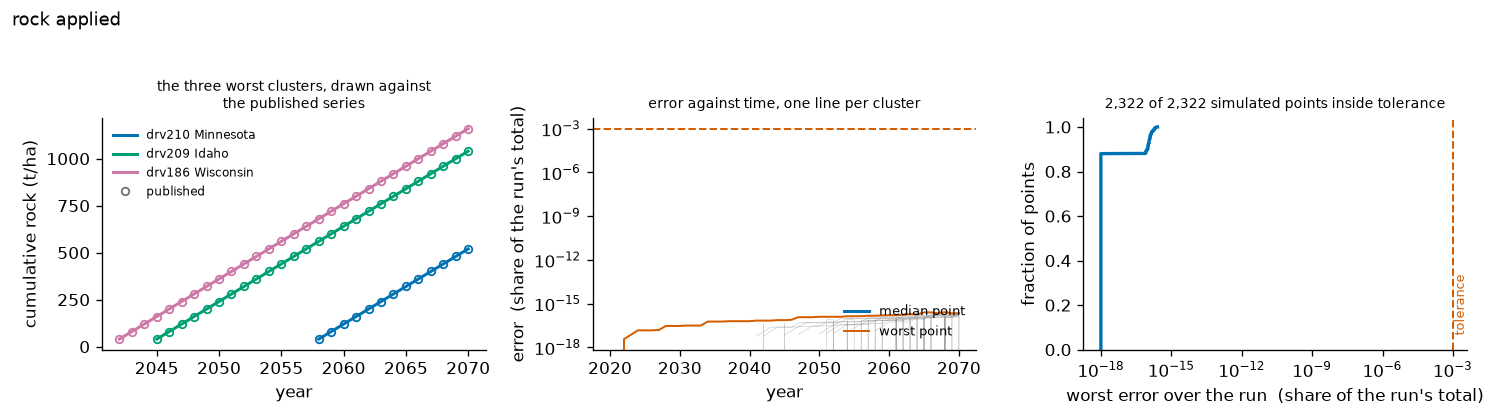

rock applied               median 0.00e+00   worst 2.58e-16 share of the run's total   (tolerance 1e-03)


In [13]:
compare("rock", ours.rock, pub.rock, "cumulative rock (t/ha)")

### 4.6 Nutrient release, P and K

P and K release are drawn from a different part of the model's state than the carbon budget, so we need to investigate them separately (i.e., even if pH and CDR are right, P and K could still be off). 

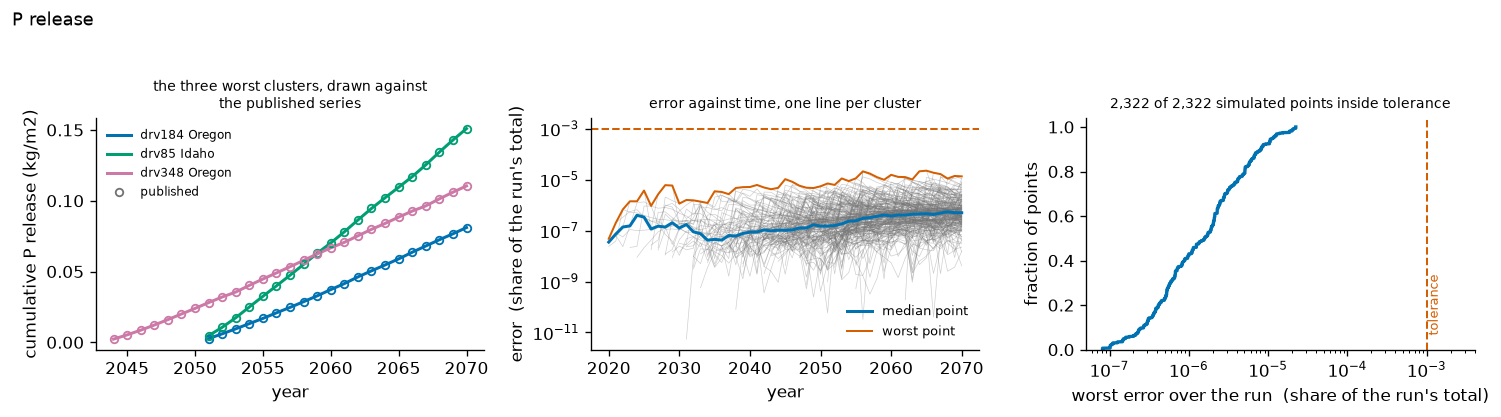

P release                  median 2.68e-07   worst 2.23e-05 share of the run's total   (tolerance 1e-03)


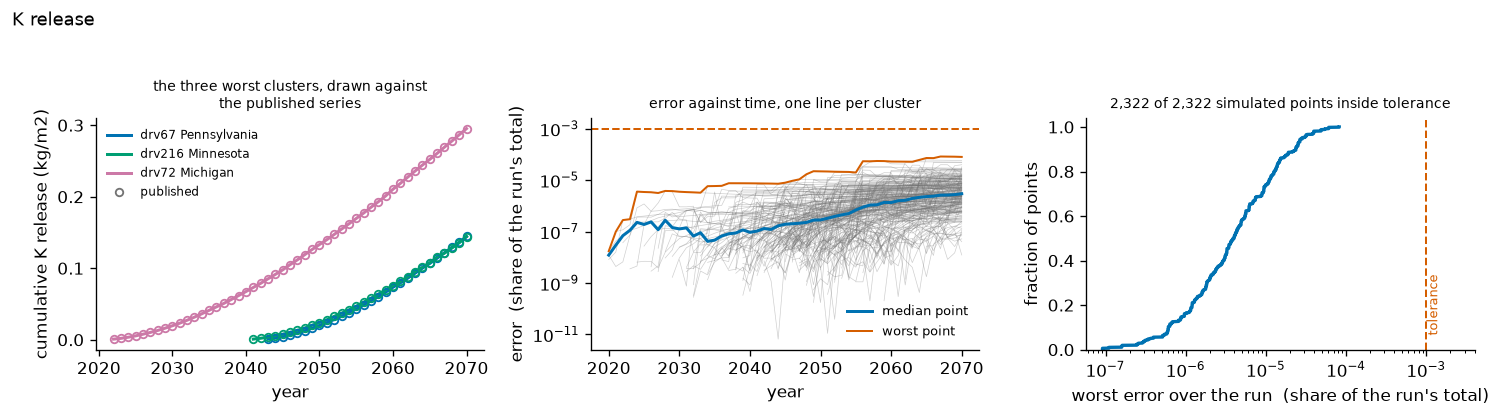

K release                  median 8.31e-07   worst 8.22e-05 share of the run's total   (tolerance 1e-03)


In [14]:
compare("P_mass", ours.P_mass, pub.P_mass, "cumulative P release (kg/m2)")
compare("K_mass", ours.K_mass, pub.K_mass, "cumulative K release (kg/m2)")

## 5. National CDR rates

The per-point checks listed above reflect pH and per-hectare fluxes. Comparison to the national CDR rates is necessary to confirm that we can scale up the cluster simulations in the same way as the original publication. 

We look at CDR rates and cumulative amounts. Both of which use the same points, so this is more of a test of the cluster-to-national pipeline than the fidelity of the individual points (which was addressed previously). 

The shaded band in the figures is the deposit's N1-N3 spread, which reflects the uncertainty envelope associated with basalt mineralogy (we did not attempt to reproduce this envelope in our simulations). The negative error (right panel) in the early 2020s is caused by the denominator. By that point there are only a handful of clusters deployed, so the national total is very small and one cluster's year-1 error becomes a notable fraction of the total.

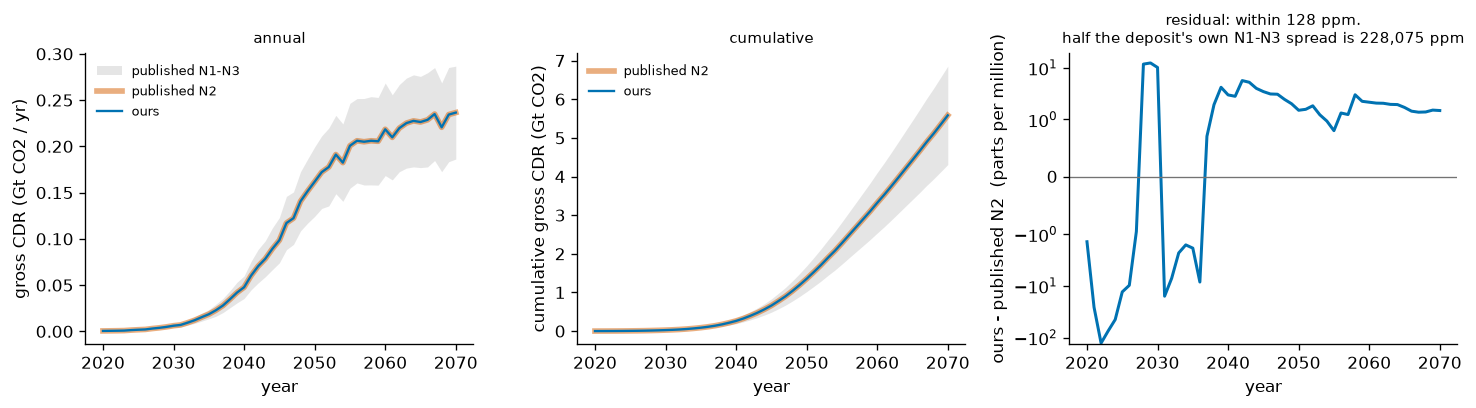

cumulative gross CDR to 2070   ours 5.5827 Gt   published 5.5827 Gt   (+1.49 ppm)
peak annual                    ours 0.2365 Gt/yr in 2070   published 0.2365 Gt/yr in 2070


In [15]:
gt = lambda x: (x * ds.area_ha).sum("point") / 1e9        # t CO2/ha -> Gt CO2
cum_o, cum_p   = gt(ours.cdr.fillna(0)), gt(pub.cdr.fillna(0))
cum_lo, cum_hi = gt(lo.cdr.fillna(0)),   gt(hi.cdr.fillna(0))
ann_o, ann_p   = annual(cum_o), annual(cum_p)

fig, axes = plt.subplots(1, 3, figsize=(12.4, 3.5))
t = ds.time

ax = axes[0]
ax.fill_between(t, annual(cum_lo), annual(cum_hi), color=OI["grey"], alpha=.18, lw=0,
                label="published N1-N3")
ax.plot(t, ann_p, color=OI["vermillion"], lw=3.4, alpha=.5, label="published N2")
ax.plot(t, ann_o, color=OI["blue"], lw=1.4, label="ours")
ax.set_xlabel("year"); ax.set_ylabel("gross CDR (Gt CO2 / yr)")
ax.set_title("annual", fontsize=9); ax.legend(frameon=False, fontsize=7.5)

ax = axes[1]
ax.fill_between(t, cum_lo, cum_hi, color=OI["grey"], alpha=.18, lw=0)
ax.plot(t, cum_p, color=OI["vermillion"], lw=3.4, alpha=.5, label="published N2")
ax.plot(t, cum_o, color=OI["blue"], lw=1.4, label="ours")
ax.set_xlabel("year"); ax.set_ylabel("cumulative gross CDR (Gt CO2)")
ax.set_title("cumulative", fontsize=9); ax.legend(frameon=False, fontsize=7.5)

ax = axes[2]
rel  = ((cum_o - cum_p) / cum_p).where(cum_p > 0) * 1e6
band = float((((cum_hi - cum_lo) / cum_p).where(cum_p > 0) * 1e6 / 2).sel(time=2070))
ax.plot(t, rel, color=OI["blue"], lw=1.8)
ax.axhline(0, color=OI["grey"], lw=.8)
ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("year"); ax.set_ylabel("ours - published N2  (parts per million)")
ax.set_title(f"residual: within {float(np.abs(rel[1:]).max()):.0f} ppm.\n"
             f"half the deposit's own N1-N3 spread is {band:,.0f} ppm", fontsize=9)

for a in axes:
    for s in ("top", "right"): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

print(f"cumulative gross CDR to 2070   ours {float(cum_o[-1]):.4f} Gt   "
      f"published {float(cum_p[-1]):.4f} Gt   ({float(rel[-1]):+.2f} ppm)")
print(f"peak annual                    ours {float(ann_o.max()):.4f} Gt/yr in "
      f"{int(t[int(ann_o.argmax())])}   published {float(ann_p.max()):.4f} Gt/yr in "
      f"{int(t[int(ann_p.argmax())])}")

### By state

Now we look at the cumulative CDR comparison by state, since deployments are broadly organized by state. 

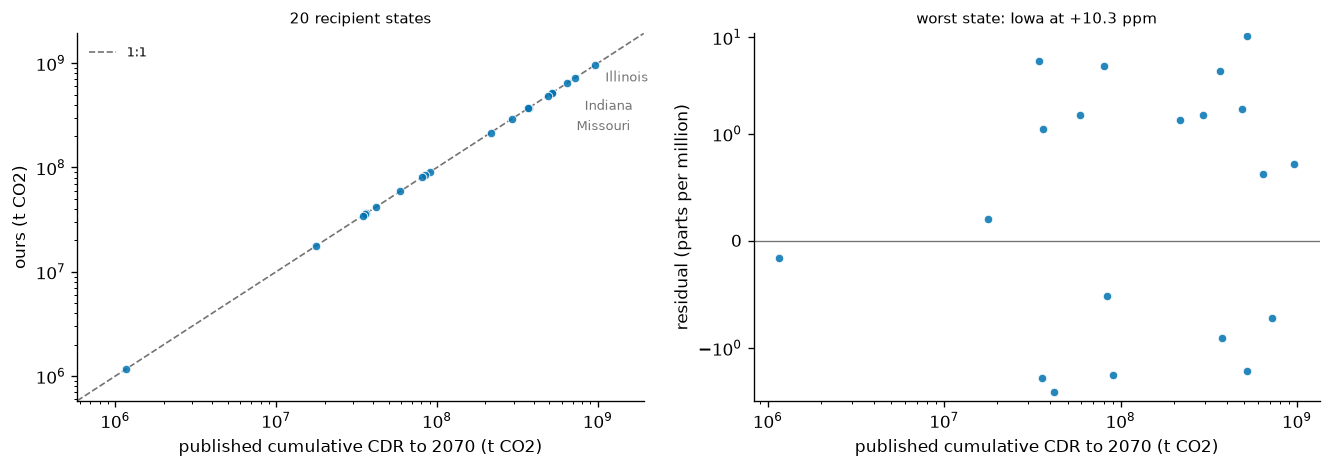

               ours       pub     ppm
state                                
Illinois  9.651e+08 9.651e+08  0.7131
Indiana   7.182e+08 7.182e+08 -0.7196
Missouri  6.393e+08 6.393e+08  0.6258
Iowa      5.203e+08 5.203e+08   10.33
Ohio      5.181e+08 5.181e+08  -1.713
Wisconsin 4.886e+08 4.886e+08   1.799
Kentucky  3.737e+08 3.737e+08 -0.9044
Minnesota 3.681e+08 3.681e+08   4.426
Michigan  2.926e+08 2.926e+08    1.58
Kansas    2.158e+08 2.158e+08   1.389


In [16]:
st = pd.DataFrame({"state": S(ds.recipient_state.values),
                   "ours": (ours.cdr.sel(time=2070) * ds.area_ha).values,
                   "pub":  (pub.cdr.sel(time=2070) * ds.area_ha).values}).fillna(0.0)
st = st.groupby("state").sum().sort_values("pub", ascending=False)
st = st[st.pub > 0]
st["ppm"] = (st.ours - st.pub) / st.pub * 1e6

fig, axes = plt.subplots(1, 2, figsize=(11.2, 4.0))

ax = axes[0]
lim = [st.pub.min() / 2, st.pub.max() * 2]
ax.plot(lim, lim, color=OI["grey"], lw=1, ls="--", zorder=1, label="1:1")
ax.scatter(st.pub, st.ours, s=26, color=OI["blue"], alpha=.85, zorder=3,
           edgecolor="white", linewidth=.6)
for j, s in enumerate(st.index[:3]):
    ax.annotate(s, (st.pub[s], st.ours[s]), textcoords="offset points",
                xytext=(6, -10 - 9 * j), fontsize=7.5, color=OI["grey"])
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("published cumulative CDR to 2070 (t CO2)")
ax.set_ylabel("ours (t CO2)")
ax.set_title(f"{len(st)} recipient states", fontsize=9); ax.legend(frameon=False, fontsize=8)

ax = axes[1]
ax.axhline(0, color=OI["grey"], lw=.8)
ax.scatter(st.pub, st.ppm, s=26, color=OI["blue"], alpha=.85, edgecolor="white", linewidth=.6)
ax.set_xscale("log"); ax.set_yscale("symlog", linthresh=1)
ax.set_xlabel("published cumulative CDR to 2070 (t CO2)")
ax.set_ylabel("residual (parts per million)")
ax.set_title(f"worst state: {st.ppm.abs().idxmax()} at "
             f"{st.ppm[st.ppm.abs().idxmax()]:+.1f} ppm", fontsize=9)

for a in axes:
    for s in ("top", "right"): a.spines[s].set_visible(False)
plt.tight_layout(); plt.show()
print(st.head(10).to_string(float_format=lambda x: f"{x:,.4g}"))

## 6. Coverage — confirming that our batch covers all deployed points


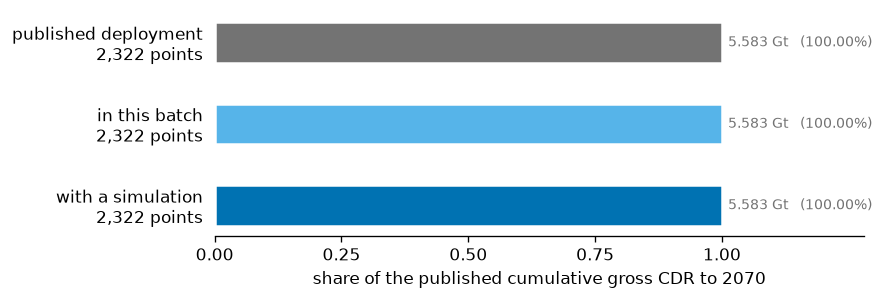

0 deployed point(s) are not in this batch at all


In [17]:
all_pts  = [p for p, v in db.items()
            if str(np.atleast_1d(v["bas"]).ravel()[SCEN - 1]) != "NaN"]
deposit  = lambda ps: np.array([db[int(p)]["CO2_a_b"][COL].values
                                for p in ps]).sum(0).cumsum()[-1] / 1e9
in_batch = mask.any("time")

# The published total is taken WITHOUT our mask at each step, so the drop from one
# row to the next is what the batch actually leaves out.
rows = [("published deployment", len(all_pts),        deposit(all_pts)),
        ("in this batch",        len(pts),            deposit(pts)),
        ("with a simulation",    int(in_batch.sum()),
                                 deposit(np.array(pts)[in_batch.values]))]
pub_all = rows[0][2]

fig, ax = plt.subplots(figsize=(7.4, 2.6))
y, share = np.arange(len(rows))[::-1], [r[2] / pub_all for r in rows]
ax.barh(y, share, height=.5, color=[OI["grey"], OI["sky"], OI["blue"]],
        edgecolor="white", linewidth=1.5)
for yi, r, s in zip(y, rows, share):
    ax.text(s + .012, yi, f"{r[2]:.3f} Gt   ({s * 100:.2f}%)", va="center", fontsize=8.5,
            color=OI["grey"])
ax.set_yticks(y, [f"{r[0]}\n{r[1]:,} points" for r in rows])
ax.set_xlim(0, 1.28); ax.set_xticks(np.arange(0, 1.01, .25))
ax.set_xlabel("share of the published cumulative gross CDR to 2070")
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(left=False)
plt.tight_layout(); plt.show()

if int((~in_batch).sum()):
    bad = sorted(set(ds.cluster.values[~in_batch.values].tolist()))
    print(f"{int((~in_batch).sum()):,} point(s) in the batch have no simulation -- "
          f"cluster(s) {bad[:10]}{' ...' if len(bad) > 10 else ''} missing a mineralogy")
print(f"{len(all_pts) - int(ds.sizes['point']):,} deployed point(s) are not in this batch at all")

## 7. Conclusions

Our `point.zarr` results reproduce the published deposit for every quantity, point, and year, inside the practical tolerance we impose. This gives us confidence that:

- The mineralogy weight, `w`, are correct.
- Our simulations strike the proper time alignment. 
- Annual values are right for both cumulative and mean pH terms.
- The area-join is right — we can scale up from a set of points to the same national number.
- The cluster-to-point join is right as we can reproduce the `pH0`. 

The biggest error is the year-1 offset of section 4.2, which is roughly fixed, non-growing difference of at most 3x10^-4 of the deployment's total CDR. 

**Two caveats**

- **N2 only.** The comparison is against the central member, N2. N1 and N3 appear in section 5 to provide a reference frame for the residual, but we have not attempted to reproduce them.
- **Gross CDR.** We do not compare or try to reproduce mining, transport, and spreading emissions, nor avoided fertilizer emissions, in the CDR calculation. 

In [ ]:
# ---